In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv("retail_sales_eda_dataset.csv")

# Display the first 5 rows
data.head()

,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price_INR,Discount_Percent,Discount_Amount_INR,Total_Sales_INR,Profit_INR,Region,Customer_Gender,Payment_Method
0,ORD10111,2025-01-02,Sneakers,Clothing,5,3044.35,5,761.09,14460.66,7154.22,West,Female,UPI
1,ORD10055,2025-01-03,Novel,Books,5,238.63,5,59.66,1133.49,393.74,South,Female,Debit Card
2,ORD10361,2025-01-03,Face Wash,Beauty,1,511.81,10,51.18,460.63,230.32,Central,Female,Debit Card
3,ORD10131,2025-01-04,Mouse,Electronics,5,3568.55,10,1784.28,16058.47,3211.69,Central,Female,UPI
4,ORD10393,2025-01-05,Storage Box,Home & Kitchen,2,4185.78,10,837.16,7534.40,2678.90,East,Other,Cash


In [2]:
print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns)

print("\nDataset Information:")
data.info()

Dataset Shape: (500, 13)

Column Names:
Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity',
       'Unit_Price_INR', 'Discount_Percent', 'Discount_Amount_INR',
       'Total_Sales_INR', 'Profit_INR', 'Region', 'Customer_Gender',
       'Payment_Method'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             500 non-null    str    
 1   Order_Date           500 non-null    str    
 2   Product              500 non-null    str    
 3   Category             500 non-null    str    
 4   Quantity             500 non-null    int64  
 5   Unit_Price_INR       500 non-null    float64
 6   Discount_Percent     500 non-null    int64  
 7   Discount_Amount_INR  500 non-null    float64
 8   Total_Sales_INR      500 non-null    float64
 9   Profit_INR           500 non-null    fl

In [3]:
# Check missing values
print("Missing Values:")
print(data.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(data.duplicated().sum())

Missing Values:
Order_ID               0
Order_Date             0
Product                0
Category               0
Quantity               0
Unit_Price_INR         0
Discount_Percent       0
Discount_Amount_INR    0
Total_Sales_INR        0
Profit_INR             0
Region                 0
Customer_Gender        0
Payment_Method         0
dtype: int64

Duplicate Records:
0


In [4]:
data.describe()

,Quantity,Unit_Price_INR,Discount_Percent,Discount_Amount_INR,Total_Sales_INR,Profit_INR
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,3.048000,2358.268000,10.350000,730.079720,6321.959540,2008.025760
std,1.449793,1924.088282,7.485959,1097.115503,6358.729963,1907.276733
min,1.000000,104.410000,0.000000,0.000000,89.440000,24.200000
25%,2.000000,861.200000,5.000000,62.767500,1804.407500,648.072500
50%,3.000000,1734.825000,10.000000,322.800000,4212.205000,1313.050000
75%,4.000000,3479.920000,15.000000,918.842500,8296.842500,2760.977500
max,5.000000,7938.560000,25.000000,7914.530000,34225.300000,10343.660000


In [5]:
data.describe(include='object')

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20756\3382516499.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include='object')


,Order_ID,Order_Date,Product,Category,Region,Customer_Gender,Payment_Method
count,500,500,500,500,500,500,500
unique,500,279,25,5,5,3,5
top,ORD10111,2025-04-05,Mouse,Electronics,South,Female,UPI
freq,1,5,33,117,113,250,186


In [6]:
data.select_dtypes(include='object').describe().T

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20756\2728789409.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.select_dtypes(include='object').describe().T


,count,unique,top,freq
Order_ID,500,500,ORD10111,1
Order_Date,500,279,2025-04-05,5
Product,500,25,Mouse,33
Category,500,5,Electronics,117
Region,500,5,South,113
Customer_Gender,500,3,Female,250
Payment_Method,500,5,UPI,186


In [7]:
print("Orders by Category:")
print(data['Category'].value_counts())

print("\nOrders by Region:")
print(data['Region'].value_counts())

print("\nOrders by Payment Method:")
print(data['Payment_Method'].value_counts())

Orders by Category:
Category
Electronics       117
Clothing          112
Home & Kitchen    103
Books              86
Beauty             82
Name: count, dtype: int64

Orders by Region:
Region
South      113
West       109
North      102
East        98
Central     78
Name: count, dtype: int64

Orders by Payment Method:
Payment_Method
UPI            186
Credit Card    114
Debit Card      83
Cash            71
Net Banking     46
Name: count, dtype: int64


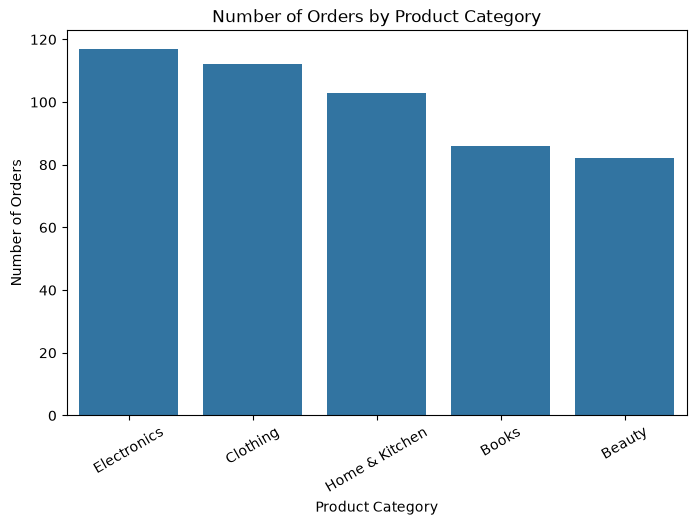

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='Category',
    order=data['Category'].value_counts().index
)

plt.title('Number of Orders by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.show()

In [9]:
# Total sales by product category
sales_by_category = data.groupby('Category')['Total_Sales_INR'].sum()

print("Total Sales by Category:")
print(sales_by_category)

Total Sales by Category:
Category
Beauty             289775.26
Books              153738.45
Clothing           621116.05
Electronics       1377814.65
Home & Kitchen     718535.36
Name: Total_Sales_INR, dtype: float64


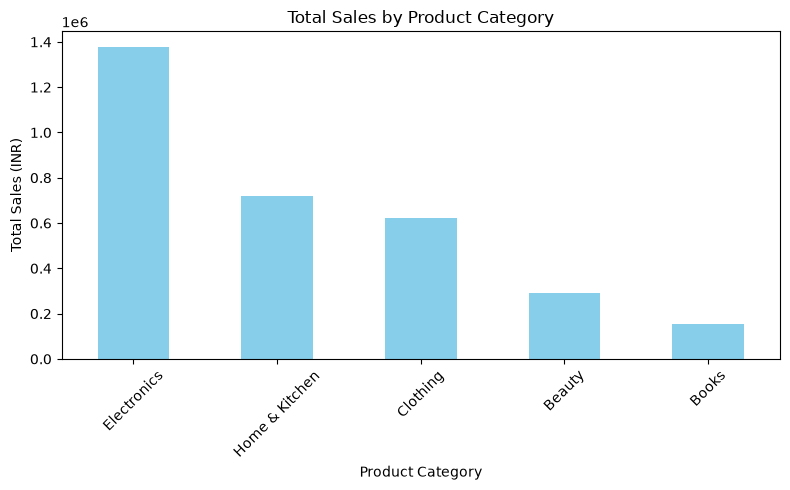

In [10]:
plt.figure(figsize=(8, 5))

sales_by_category.sort_values(ascending=False).plot(
    kind='bar',
    color='skyblue'
)

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Convert Order_Date to datetime format
data['Order_Date'] = pd.to_datetime(data['Order_Date'])

# Extract month
data['Month'] = data['Order_Date'].dt.month

# Calculate monthly sales
monthly_sales = data.groupby('Month')['Total_Sales_INR'].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
1     229044.86
2     229191.01
3     204388.75
4     390747.89
5     277883.81
6     335060.80
7     267135.30
8     180459.91
9     252491.42
10    268984.95
11    217862.26
12    307728.81
Name: Total_Sales_INR, dtype: float64


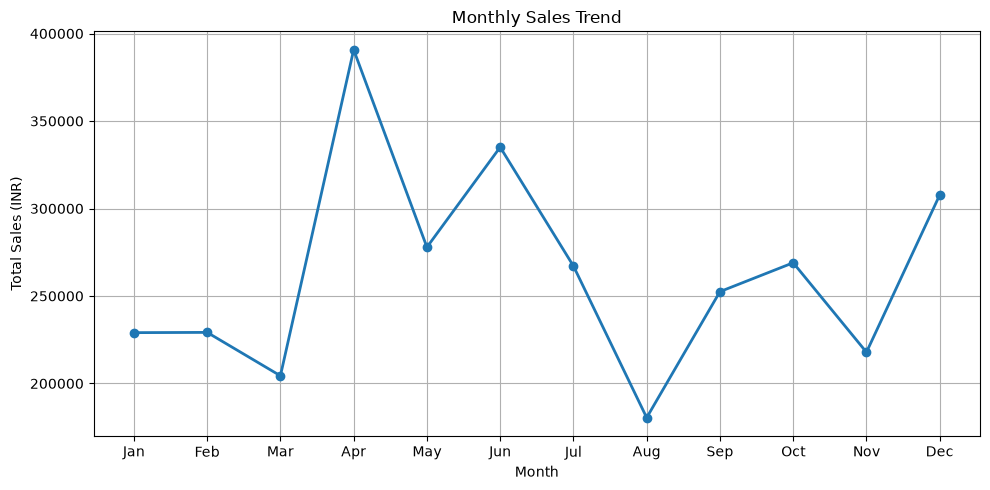

In [12]:
import calendar

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (INR)')
plt.xticks(
    range(1, 13),
    [calendar.month_abbr[i] for i in range(1, 13)]
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
sales_by_region = data.groupby('Region')['Total_Sales_INR'].sum().sort_values(ascending=False)

print("Total Sales by Region:")
print(sales_by_region)

Total Sales by Region:
Region
South      776970.34
West       696040.44
North      652964.51
East       621468.54
Central    413535.94
Name: Total_Sales_INR, dtype: float64


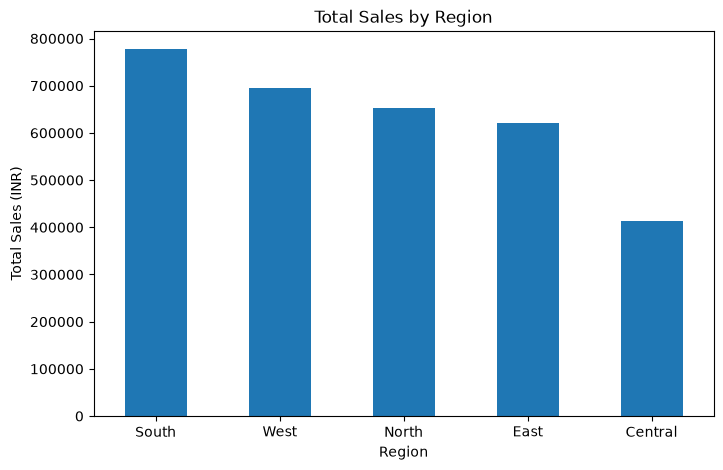

In [14]:
plt.figure(figsize=(8, 5))

sales_by_region.plot(kind='bar')

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales (INR)')
plt.xticks(rotation=0)

plt.show()

In [15]:
average_sales_by_payment = data.groupby('Payment_Method')['Total_Sales_INR'].mean().sort_values(ascending=False)

print("Average Sales by Payment Method:")
print(average_sales_by_payment)

Average Sales by Payment Method:
Payment_Method
Debit Card     6917.936747
UPI            6669.901667
Cash           6364.675352
Credit Card    5721.513070
Net Banking    5261.845000
Name: Total_Sales_INR, dtype: float64


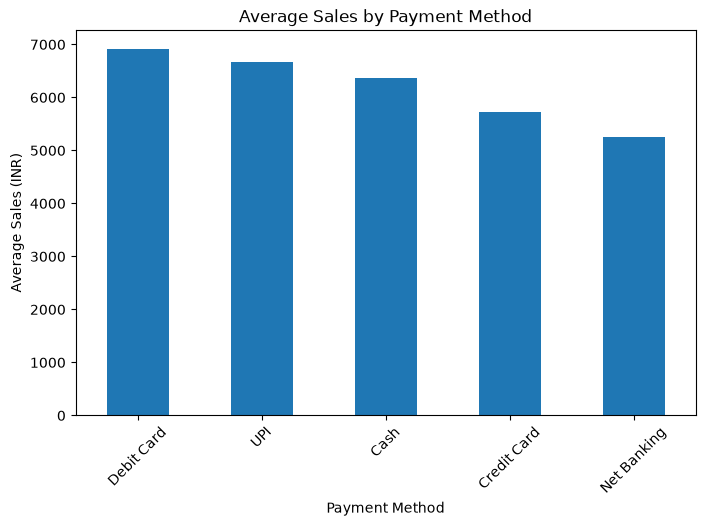

In [16]:
plt.figure(figsize=(8, 5))

average_sales_by_payment.plot(kind='bar')

plt.title('Average Sales by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Average Sales (INR)')
plt.xticks(rotation=45)

plt.show()

In [17]:
monthly_orders = data.groupby('Month')['Order_ID'].count()

print("Monthly Order Count:")
print(monthly_orders)

Monthly Order Count:
Month
1     42
2     41
3     33
4     63
5     51
6     48
7     40
8     30
9     34
10    38
11    35
12    45
Name: Order_ID, dtype: int64


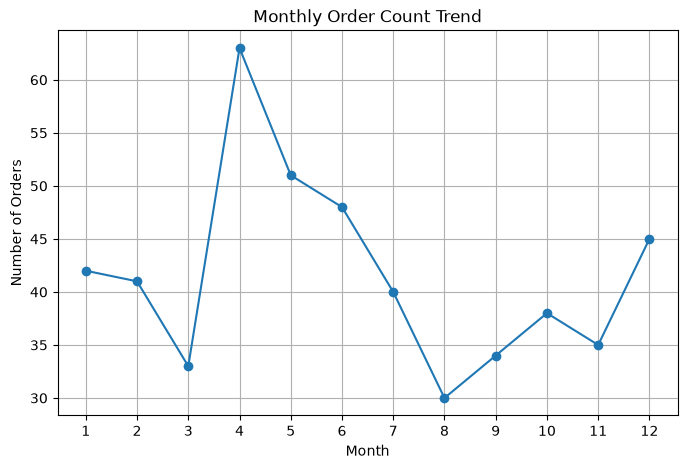

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(monthly_orders.index, monthly_orders.values, marker='o')

plt.title("Monthly Order Count Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [19]:
payment_counts = data['Payment_Method'].value_counts()

print("Number of Orders by Payment Method:")
print(payment_counts)

Number of Orders by Payment Method:
Payment_Method
UPI            186
Credit Card    114
Debit Card      83
Cash            71
Net Banking     46
Name: count, dtype: int64


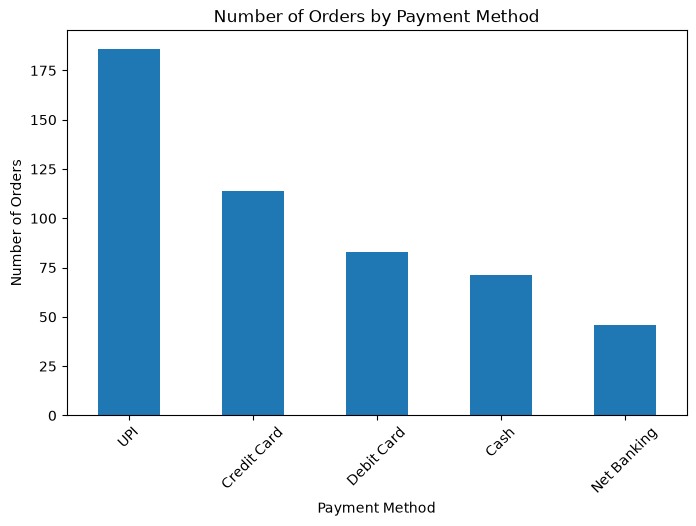

In [20]:
plt.figure(figsize=(8, 5))

payment_counts.plot(kind='bar')

plt.title("Number of Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

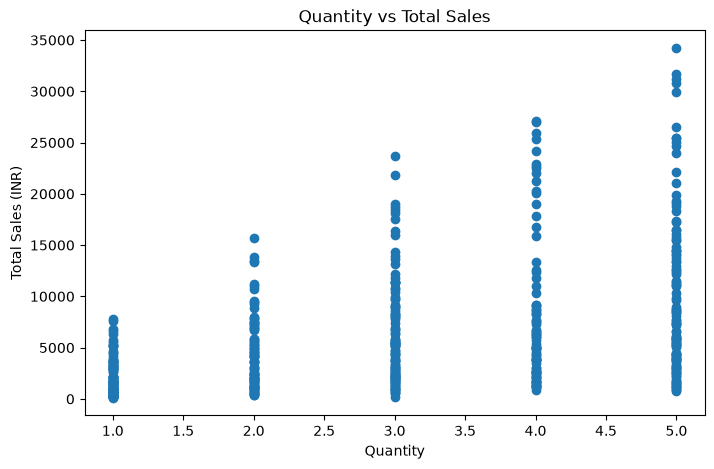

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(data['Quantity'], data['Total_Sales_INR'])

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales (INR)")

plt.show()

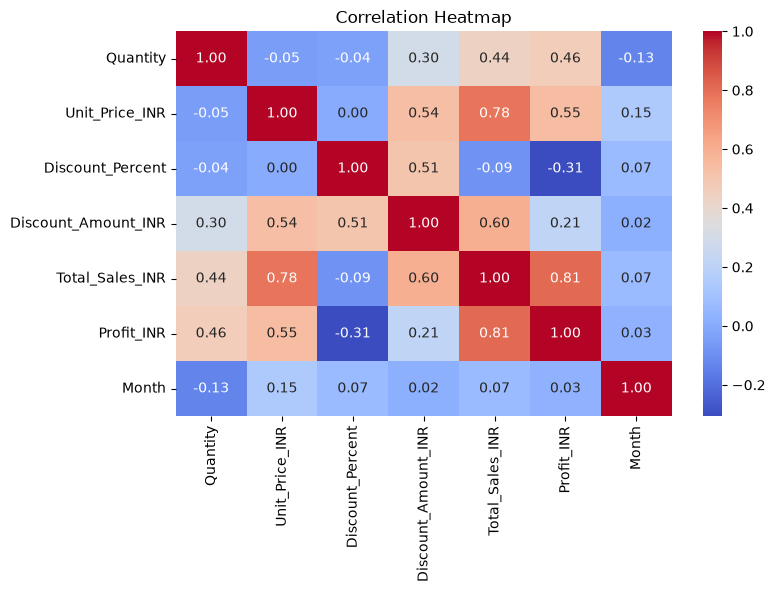

In [22]:
numeric_data = data.select_dtypes(include='number')

plt.figure(figsize=(8, 5))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

## Key Findings from Exploratory Data Analysis

1. Monthly sales fluctuate throughout the year.
2. Sales performance differs across regions.
3. UPI is the most frequently used payment method in the dataset.
4. Monthly order counts vary, with some months recording more orders than others.
5. Higher quantities are generally associated with higher total sales.
6. Total Sales and Profit have a strong positive correlation of 0.81.
7. Unit Price and Total Sales have a positive correlation of 0.78.
8. Discount Percentage has a negative correlation with Profit (-0.31).

## Conclusion

The exploratory data analysis helped identify sales trends,
customer payment preferences, regional performance, and
relationships between numerical variables.